# 3. Drift and retraining

A model trained once decays as fraud patterns change. The *retrain* schedule refits the model on all labels known at each cut-off (older than the embargo).

In [1]:
%matplotlib inline
from pipeline.notebook_support import *
import pandas as pd
import numpy as np
pd.set_option('display.width', 160)
drift = load_results('drift_weekly.csv')
summary = load_results('drift_summary.csv')
summary.round(4)

,kind,schedule,mean_pr_auc,slope_per_week,config_hash,fixture
0,gnn_fraud_only,retrain,0.3524,-0.0010,2098e521aa7d,False
1,gnn_fraud_only,static,0.3583,0.0016,2098e521aa7d,False
2,history_stable_tabular,retrain,0.4708,0.0036,2098e521aa7d,False
3,history_stable_tabular,static,0.4685,0.0014,2098e521aa7d,False
4,history_tabular,retrain,0.4684,0.0068,2098e521aa7d,False
5,history_tabular,static,0.4477,0.0006,2098e521aa7d,False


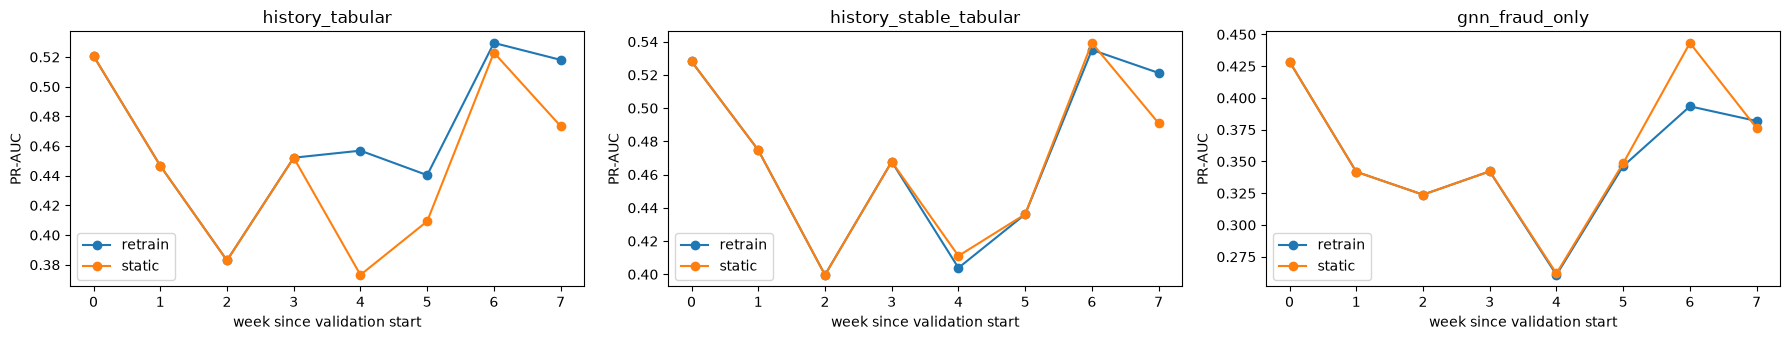

In [2]:
plot_drift(drift);

A negative `slope_per_week` for *static* means the frozen model gets worse each week. If *retrain* is not better, then on this data retraining did not help; report that as it is.